# Data Preparation

In [27]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
# load dataset
df = pd.read_csv("data.csv", sep=";")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [29]:
# check missing values
print("Missing values:", df.isnull().sum().sum())

Missing values: 0


In [30]:
# check duplicate records
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [31]:
# target class distribution
print(f"Target Distribution: {df['Target'].value_counts()}")

Target Distribution: Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [32]:
# input features and target variable
X = df.drop("Target", axis=1)
y = df["Target"]

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (4424, 36)
Target variable: (4424,)


# Training and Testing

In [33]:
# split data into 80% training and 20% testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training sample:", len(X_train))
print("Testing sample:", len(X_test))

Training sample: 3539
Testing sample: 885


# Preprocessing

In [34]:
# identify categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

print("Categorical features:", len(categorical_cols))
print("Numerical features:", X.shape[1] - len(categorical_cols))

Categorical features: 17
Numerical features: 19


In [35]:
# one-hot encoding for categorical features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

# Model Training

In [36]:
# import Random Forest and Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# create the pipeline model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [37]:
# train the model
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Dropout','Enrolled','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['Marital status','Application mode','Application order',..., 'Unemployment rate','Inflation rate','GDP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'d

# Evaluation

In [38]:
# predict outcomes using test data
y_pred = model.predict(X_test)

print("Total predictions:", len(y_pred))

Total predictions: 885


In [39]:
# evaluate model performance
from sklearn.metrics import classification_report, accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {round(accuracy * 100, 2)}%")

Model Accuracy: 76.16%


In [40]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.78       284
    Enrolled       0.58      0.26      0.36       159
    Graduate       0.77      0.94      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.66      0.66       885
weighted avg       0.74      0.76      0.74       885



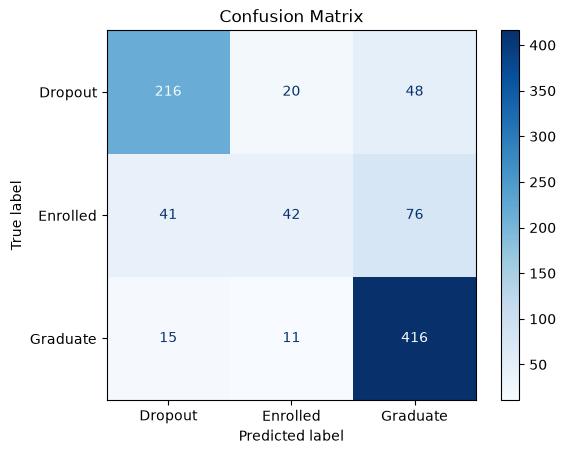

In [41]:
# Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

# Cross-Validation

In [42]:
# evaluate the model with 5-fold cross-validation
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")

print(f"Cross-validation scores: {cv_scores.round(4)}")
print(f"Mean accuracy: {round(cv_scores.mean() * 100, 2)}%")
print(f"Standard deviation: {round(cv_scores.std() * 100, 2)}%")

Cross-validation scores: [0.7952 0.7599 0.7867 0.75   0.7723]
Mean accuracy: 77.28%
Standard deviation: 1.66%
